# 03 — Comparaison des modèles MachineEar

**Objectif :** comparer Isolation Forest, One-Class SVM et Random Forest sur les mêmes enregistrements `id_00` (0 dB).

- Isolation Forest et One-Class SVM apprennent **uniquement sur les sons normaux**.
- Random Forest est **supervisé** et utilise les deux classes à l’entraînement.
- Les hyperparamètres sont choisis sur **validation**, le test est utilisé **une seule fois** à la fin.
- Seuil de décision calibré sur les sons normaux de validation pour viser **5 % de fausses alertes**.

⚠️ Cette comparaison sur un seul identifiant de machine et avec une séparation aléatoire est exploratoire. Des enregistrements proches peuvent être corrélés. Pour un résultat de PFE solide, évaluer ensuite sur des identifiants/machines et conditions acoustiques indépendants.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve,
                             precision_recall_curve)

SEED = 42
TARGET_FPR = 0.05
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CSV_PATH = ROOT / "data" / "processed" / "fan_id00_features.csv"
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
assert CSV_PATH.exists(), f"CSV introuvable : {CSV_PATH}"
print("CSV :", CSV_PATH)

CSV : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\processed\fan_id00_features.csv


In [2]:
df = pd.read_csv(CSV_PATH)
assert "label" in df.columns and set(df["label"].dropna().unique()) == {0, 1}
assert df["label"].notna().all()
if "file_path" in df.columns:
    assert not df["file_path"].duplicated().any(), "Chemins dupliqués"
excluded = {"file_path", "label", "duration_sec"}
features = [c for c in df.select_dtypes(include="number").columns if c not in excluded]
X = df[features].copy()
y = df["label"].astype(int)
assert len(features) > 0
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Valeurs non finies détectées"
print(f"{len(df)} fichiers, {len(features)} caractéristiques")
print(y.value_counts().rename(index={0:"Normal",1:"Anormal"}))

1418 fichiers, 52 caractéristiques
label
Normal     1011
Anormal     407
Name: count, dtype: int64


## 1 — Séparation commune aux trois modèles

60 % des sons normaux et 60 % des sons anormaux pour l’entraînement supervisé ; 20 % de chaque classe en validation et 20 % en test. Les deux méthodes non supervisées ignorent les anomalies de leur ensemble d’entraînement. Les indices sont enregistrés pour reproductibilité.

**Important :** le jeu de test sera comparable entre les trois modèles de ce notebook, mais pas nécessairement identique à celui du notebook 02.

In [3]:
normal = df.index[y == 0].to_numpy()
abnormal = df.index[y == 1].to_numpy()
def split_60_20_20(indices):
    train, temp = train_test_split(indices, test_size=0.4, random_state=SEED)
    val, test = train_test_split(temp, test_size=0.5, random_state=SEED)
    return train, val, test
n_train, n_val, n_test = split_60_20_20(normal)
a_train, a_val, a_test = split_60_20_20(abnormal)
train_all = np.concatenate([n_train, a_train])
val_idx = np.concatenate([n_val, a_val])
test_idx = np.concatenate([n_test, a_test])
assert not(set(train_all) & set(val_idx) or set(train_all) & set(test_idx) or set(val_idx) & set(test_idx))
print("Train :",len(train_all),"(normaux",len(n_train),"; anormaux",len(a_train),")")
print("Validation :",len(val_idx)," | Test :",len(test_idx))

Train : 850 (normaux 606 ; anormaux 244 )
Validation : 283  | Test : 285


## 2 — Entraînement et sélection sur validation

Pour les détecteurs non supervisés, les scores les plus élevés indiquent une anomalie. Pour Random Forest, on utilise la probabilité prédite de la classe `1`. Les paramètres sont choisis en maximisant le **ROC-AUC de validation** ; cela utilise les étiquettes de validation, mais jamais celles du test.

In [4]:
candidates = []
for trees in (200, 400):
    for max_samples in (0.5, 1.0):
        candidates.append((f"IsolationForest_t{trees}_s{max_samples}",
            Pipeline([("scaler",StandardScaler()),("model",IsolationForest(
                n_estimators=trees,max_samples=max_samples,contamination="auto",
                random_state=SEED,n_jobs=-1))]), "unsupervised"))
for nu in (0.02, 0.05, 0.10):
    for gamma in ("scale", 0.01):
        candidates.append((f"OneClassSVM_nu{nu}_g{gamma}",
            Pipeline([("scaler",StandardScaler()),("model",OneClassSVM(nu=nu,gamma=gamma))]), "unsupervised"))
for depth in (None, 8, 16):
    for leaf in (1, 3):
        candidates.append((f"RandomForest_depth{depth}_leaf{leaf}",
            RandomForestClassifier(n_estimators=300,max_depth=depth,min_samples_leaf=leaf,
                                   class_weight="balanced",random_state=SEED,n_jobs=-1),"supervised"))

def get_scores(model, kind, data):
    if kind == "supervised":
        return model.predict_proba(data)[:,list(model.classes_).index(1)]
    if kind == "unsupervised":
        return -model.score_samples(data)
    raise ValueError(kind)

results_val = []
trained = {}
for name, model, kind in candidates:
    fit_idx = n_train if kind == "unsupervised" else train_all
    model.fit(X.loc[fit_idx], y.loc[fit_idx] if kind == "supervised" else None)
    scores = get_scores(model, kind, X.loc[val_idx])
    auc = roc_auc_score(y.loc[val_idx],scores)
    ap = average_precision_score(y.loc[val_idx],scores)
    results_val.append({"candidate":name,"family":name.split("_")[0],"val_roc_auc":auc,"val_pr_auc":ap})
    trained[name] = (model,kind)
val_table = pd.DataFrame(results_val).sort_values("val_roc_auc",ascending=False)
display(val_table.round(4))

,candidate,family,val_roc_auc,val_pr_auc
13,RandomForest_depth8_leaf3,RandomForest,0.9930,0.9834
12,RandomForest_depth8_leaf1,RandomForest,0.9926,0.9834
10,RandomForest_depthNone_leaf1,RandomForest,0.9925,0.9832
14,RandomForest_depth16_leaf1,RandomForest,0.9925,0.9832
15,RandomForest_depth16_leaf3,RandomForest,0.9914,0.9827
11,RandomForest_depthNone_leaf3,RandomForest,0.9914,0.9827
4,OneClassSVM_nu0.02_gscale,OneClassSVM,0.8048,0.7375
6,OneClassSVM_nu0.05_gscale,OneClassSVM,0.8047,0.7374
8,OneClassSVM_nu0.1_gscale,OneClassSVM,0.8027,0.7287
9,OneClassSVM_nu0.1_g0.01,OneClassSVM,0.7965,0.7207


## 3 — Seuils fixés sur validation, sans toucher au test

Pour chaque famille, on conserve le meilleur candidat d’après le ROC-AUC de validation. On fixe son seuil au quantile 95 % des scores des **normaux de validation**. Le FPR réel de test peut différer de 5 %.

In [5]:
selected = {}
for family in ("IsolationForest","OneClassSVM","RandomForest"):
    row = val_table[val_table["family"] == family].iloc[0]
    name = row["candidate"]
    model,kind = trained[name]
    vscores = get_scores(model,kind,X.loc[val_idx])
    normal_scores = vscores[y.loc[val_idx].to_numpy() == 0]
    threshold = float(np.quantile(normal_scores,1-TARGET_FPR))
    selected[family] = {"name":name,"model":model,"kind":kind,"threshold":threshold,
                        "val_auc":float(row["val_roc_auc"])}
    print(f"{family}: {name}, ROC-AUC validation={row['val_roc_auc']:.4f}, seuil={threshold:.5f}")

IsolationForest: IsolationForest_t200_s1.0, ROC-AUC validation=0.7257, seuil=0.49817
OneClassSVM: OneClassSVM_nu0.02_gscale, ROC-AUC validation=0.8048, seuil=-0.24952
RandomForest: RandomForest_depth8_leaf3, ROC-AUC validation=0.9930, seuil=0.40944


## 4 — Évaluation finale sur test (une seule fois)

In [6]:
test_y = y.loc[test_idx].to_numpy()
rows = []
score_curves = {}
for family, info in selected.items():
    scores = get_scores(info["model"],info["kind"],X.loc[test_idx])
    preds = (scores > info["threshold"]).astype(int)
    tn,fp,fn,tp = confusion_matrix(test_y,preds,labels=[0,1]).ravel()
    rows.append({"model":family,"roc_auc":roc_auc_score(test_y,scores),
                 "pr_auc":average_precision_score(test_y,scores),
                 "fpr":fp/(fp+tn),"recall_anomaly":tp/(tp+fn),
                 "precision_anomaly":tp/(tp+fp) if tp+fp else 0,
                 "f1_anomaly":2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0,
                 "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)})
    score_curves[family] = scores
metrics = pd.DataFrame(rows).sort_values("roc_auc",ascending=False)
display(metrics.round(4))
for family, scores in score_curves.items():
    pred = (scores > selected[family]["threshold"]).astype(int)
    print("\n",family,"\n",classification_report(test_y,pred,target_names=["Normal","Anormal"],zero_division=0))

,model,roc_auc,pr_auc,fpr,recall_anomaly,precision_anomaly,f1_anomaly,TN,FP,FN,TP
2,RandomForest,0.9686,0.9474,0.0985,0.9268,0.7917,0.8539,183,20,6,76
1,OneClassSVM,0.7316,0.6577,0.0394,0.4268,0.8140,0.5600,195,8,47,35
0,IsolationForest,0.6776,0.4231,0.0591,0.0976,0.4000,0.1569,191,12,74,8



 IsolationForest 
               precision    recall  f1-score   support

      Normal       0.72      0.94      0.82       203
     Anormal       0.40      0.10      0.16        82

    accuracy                           0.70       285
   macro avg       0.56      0.52      0.49       285
weighted avg       0.63      0.70      0.63       285


 OneClassSVM 
               precision    recall  f1-score   support

      Normal       0.81      0.96      0.88       203
     Anormal       0.81      0.43      0.56        82

    accuracy                           0.81       285
   macro avg       0.81      0.69      0.72       285
weighted avg       0.81      0.81      0.79       285


 RandomForest 
               precision    recall  f1-score   support

      Normal       0.97      0.90      0.93       203
     Anormal       0.79      0.93      0.85        82

    accuracy                           0.91       285
   macro avg       0.88      0.91      0.89       285
weighted avg       0.

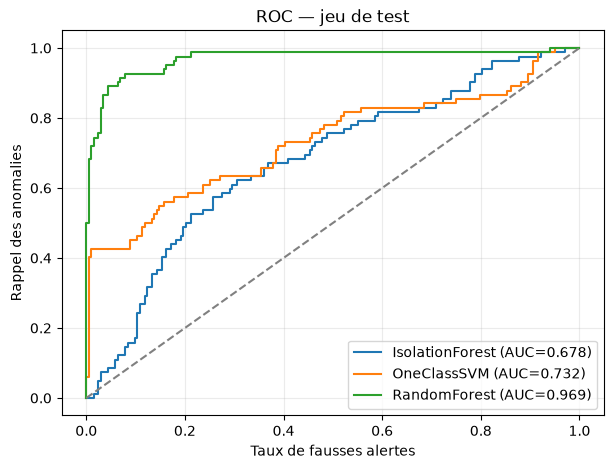

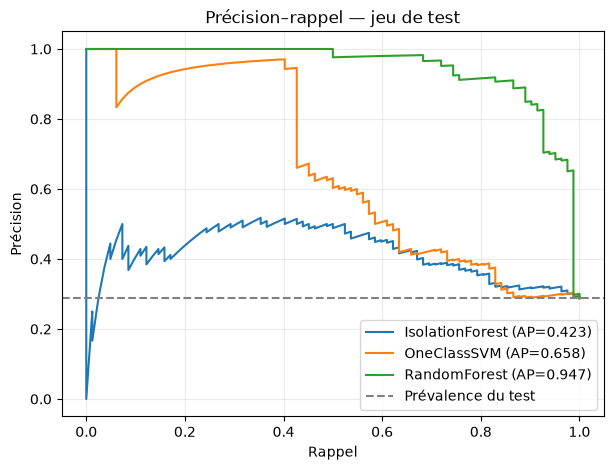

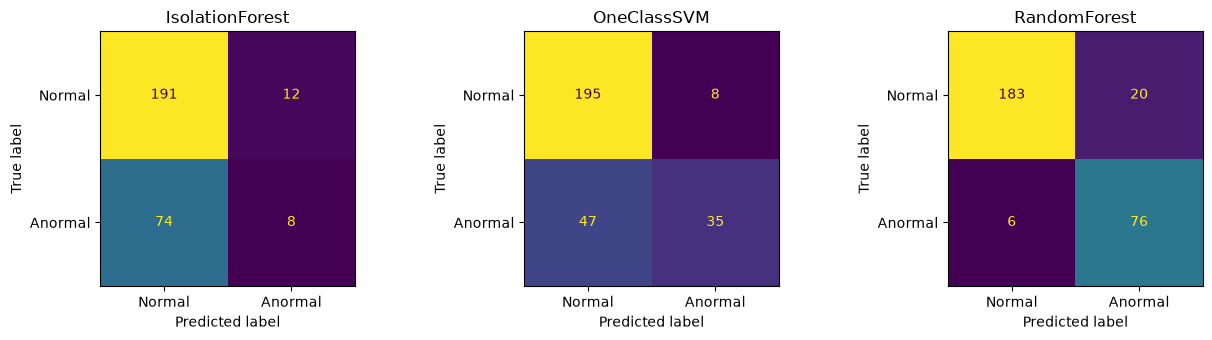

In [7]:
fig, ax = plt.subplots(figsize=(7,5))
for family,scores in score_curves.items():
    fpr,tpr,_ = roc_curve(test_y,scores)
    ax.plot(fpr,tpr,label=f"{family} (AUC={roc_auc_score(test_y,scores):.3f})")
ax.plot([0,1],[0,1],"--",color="gray")
ax.set(xlabel="Taux de fausses alertes",ylabel="Rappel des anomalies",title="ROC — jeu de test")
ax.legend();ax.grid(alpha=.25);plt.show()
fig, ax = plt.subplots(figsize=(7,5))
for family,scores in score_curves.items():
    precision,recall,_ = precision_recall_curve(test_y,scores)
    ax.plot(recall,precision,label=f"{family} (AP={average_precision_score(test_y,scores):.3f})")
ax.axhline(test_y.mean(),linestyle="--",color="gray",label="Prévalence du test")
ax.set(xlabel="Rappel",ylabel="Précision",title="Précision–rappel — jeu de test")
ax.legend();ax.grid(alpha=.25);plt.show()
fig,axes = plt.subplots(1,3,figsize=(13,3.5))
for ax,(family,scores) in zip(axes,score_curves.items()):
    pred = (scores > selected[family]["threshold"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(test_y,pred,labels=[0,1],display_labels=["Normal","Anormal"],ax=ax,colorbar=False)
    ax.set_title(family)
plt.tight_layout();plt.show()

## 5 — Sauvegarder les modèles et résultats

Les modèles sont enregistrés avec leur liste de caractéristiques et le seuil validé. **Ne charge jamais un fichier `.joblib` d’une source inconnue.**

In [8]:
for family,info in selected.items():
    out = MODEL_DIR / f"{family.lower()}_fan_id00.joblib"
    joblib.dump({"pipeline":info["model"],"feature_columns":features,
                 "threshold":info["threshold"],"score_type":info["kind"],
                 "selected_candidate":info["name"],"target_validation_fpr":TARGET_FPR},out)
    print("Enregistré :",out)
metrics.to_csv(MODEL_DIR / "comparison_metrics.csv",index=False)
pd.DataFrame({"row_index":np.concatenate([train_all,val_idx,test_idx]),
              "split":(["train"]*len(train_all)+["validation"]*len(val_idx)+["test"]*len(test_idx))}).to_csv(
                  MODEL_DIR / "comparison_splits.csv",index=False)
print("Résultats :",MODEL_DIR / "comparison_metrics.csv")

Enregistré : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\isolationforest_fan_id00.joblib
Enregistré : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\oneclasssvm_fan_id00.joblib
Enregistré : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\randomforest_fan_id00.joblib
Résultats : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\models\comparison_metrics.csv


## Comment interpréter les résultats ?

- **ROC-AUC** : qualité du classement des anomalies indépendamment du seuil.
- **Rappel** : part des anomalies effectivement détectées.
- **FPR** : part des sons normaux signalés à tort.
- **PR-AUC** : dépend aussi de la proportion d’anomalies dans le jeu de test.

**Suite recommandée :** comparer la robustesse sur `id_02`, `id_04`, `id_06` et d’autres niveaux de bruit, puis tester des représentations temporelles/spectrogrammes. Ne pas présenter les résultats de cette séparation aléatoire comme une preuve de généralisation industrielle.